# 第十轮：条件混合与历史 RET 状态

本轮所有比较保持完整2,588场、原标签和0.5阈值。新对照最高观察为
**1708/2,588 = 66.00%**（`ret_RC_spline`）；
这不改变较早数据冻结的选择。连同旧条件参考，表中最高仍是
**1760/2,588 = 68.01%**（2023最高观察准确率，未选中，loss更差），
距1,812场目标差**52**场。
2023与2022门槛已重复使用，结果均为探索性；2024–2025继续封存，goal保持进行中。

## 同一批比赛的对比

| 条件与角色 | 正确 / 2,588 | Accuracy | Log loss ↓ | 距70%正确数 |
| --- | ---: | ---: | ---: | ---: |
| 原历史输入 / 旧基准：排名 logistic 原基准（`rank_reference`） | 1640 | 63.37% | 0.629796 | 172 |
| 原历史输入 / 旧基准：R4：保留的纯历史概率推荐（`previous_probability_recommendation`） | 1696 | 65.53% | 0.609407 | 116 |
| 原历史输入 / 旧基准：R5：冻结准确率探索组合（`previous_round5_exploration`） | 1715 | 66.27% | 0.609871 | 97 |
| 原历史输入 / 旧基准：整体 Elo 原基准（开发期选 K=32）（`raw_elo_k32_diff`） | 1640 | 63.37% | 0.639146 | 172 |
| 历史输入；训练期市场监督：R7：市场监督学生（`market_lambda1`） | 1712 | 66.15% | 0.604599 | 100 |
| 当前开盘价＋T−21历史修正；缺失回退R4：2023最高观察准确率，未选中，loss更差（`history_linear_C0.03_alpha1`） | 1760 | 68.01% | 0.596723 | 52 |
| 当前末盘价优先；缺失用开盘或R4回退：固定对照 / 既有模型；分支保留推荐（`raw_market`） | 1752 | 67.70% | 0.587691 | 60 |
| T−21纯历史：固定专家组合：预设新对照（`equal_mix`） | 1687 | 65.19% | 0.606512 | 125 |
| T−21纯历史：固定专家组合：预设新对照（`global_mix`） | 1684 | 65.07% | 0.607014 | 128 |
| T−21纯历史：固定专家组合：预设新对照（`conditional_mix`） | 1684 | 65.07% | 0.607024 | 128 |
| T−21历史；含提供方RET状态，来源部分核验：预设新对照（`ret_RC_spline`） | 1708 | 66.00% | 0.605707 | 104 |
| T−21历史；含提供方RET状态，来源部分核验：预设新对照（`ret_R_spline`） | 1707 | 65.96% | 0.605856 | 105 |
| T−21纯历史对照/旧参考：预设新对照；pooled开发期冻结选择（`ret_I_spline`） | 1704 | 65.84% | 0.606294 | 108 |



当前市场参考使用较晚信息，历史市场监督学生使用额外训练监督，分别保留原有条件。
纯历史输入、历史RET状态与当前报价不能合并成同一信息条件下的升级宣称。

## 条件权重是否有用

四个冻结原始专家的概率完全相同，比较等权、全局权重和五项赛前上下文控制的权重。
先用2020 OOF拟合、2021选方法，再检查2022门槛；没有伪造2020的元模型测试，
没有pooled重选。真实前向比较4,916场，最终拟合用6,130个原始OOF预测。
三阶段各一套全局与条件优化，共**6次优化、零次基础模型重训**。

2021冻结选择为`round4_reference`。2023全局混合正确1684场、
loss0.607014；条件混合正确1684场、
loss0.607024。
应以条件与全局的配对差异判断路由机制，不能只拿它与更弱的单个专家比较。
[门控报告](results/round10/gating/report_summary.md)保存三阶段权重变化、配对区间及全部失败结果。

## 历史 RET 是否超出普通休赛信息

I/R/RC恰好三个固定结构，三年前向fold加最终拟合，共**12次拟合**；无事后混合。
三组共享326旧字段和6个普通inactivity字段。R与RC各增4个RET字段，输入维数
332/336/336；I是嵌套基线，只有R与RC同容量。
RET只表示已记录的过去非完赛，不是伤病诊断或恢复概率；不使用当前目标的RET，
也不把其未完成技术统计或额外败局加进普通历史。

2023的I/R/RC分别判对1704/
1707/1708场。
较早2020–2021选择R，但2022仅比R4多
5场，没有达到升级门槛；
pooled开发期选择的是I。加入RET在2023有小幅loss和准确率改善，但pooled前向准确率
并未超过I，不能据此断言RET有稳定增益，也不事后改选RC。

30条预先冻结来源样本中，**10条官方核实，20条仍未核实**，且已核实部分偏早期。
未核实记录既不假称通过，也不按官方文档是否易得而筛选。协调者在看新分数前
授权了带此限制的有限探索，来源全面ready标志仍为false。
完整候选、差异和冻结选择见[RET报告](results/round10/retirement/report_summary.md)；
来源证据与边界见[协议](docs/research/round10_retirement_protocol.md)。

## 冻结选择与建议

| 分支 | 较早数据冻结选择 | 2022流程决定 | 2023冻结探索正确数 |
| --- | --- | --- | ---: |
| gating | `round4_reference` | `retain_round4` | 1696 |
| retirement | `ret_I_spline` | `retain_round4` | 1704 |

门控的2021方法选择与RET的pooled开发期探索不是相同选择程序；RET的实际升级
仍由2020–2021早选后在2022检查。各分支保留/采用的是
`round4_reference`与`previous_probability_recommendation`。
维持所有既有信息条件及排名/Elo基准，不以2023最优观察覆盖冻结决定。

## 更近历史的来源试点

六组预先指定的2021–2022赛事衔接中，4组通过保守日期界限，
3个来源赛事能新增历史，直接覆盖所列
544场中的204场。
两组相邻日期因为保守时区界限重叠被拒绝，一组虽已完赛但原T−21就已可用。
这是元数据可行性，不是预测提升；网页历史发布日期仍有证据层级限制。
没有因此缩短全局滞后或训练新模型。
[逐条证据和计数](docs/research/round10_completion_feasibility.md)。
独立复核保存了下一步完整来源工作清单：2021–2022共127个目标赛事、504个候选转移，
包括没有候选来源的赛事；2023的259个候选转移单列，全部尚未获准用于预测。
[独立复核与采样框](docs/research/round10_completion_review.md)。

## 核验与复跑

基础测试329通过，8个可选Torch跳过，
97子测试通过。本轮未修改神经网络训练或重跑其旧实验。
两个独立模型审计分别保存在[gating](results/round10/gating/artifact_audit.json)和
[retirement](results/round10/retirement/artifact_audit.json)。门控审计独立检查全部4,916 OOF与
2,588验证行、六个优化结果、训练期标准化和前向计算；原R4/R5旧fold模型未保存的
限制继续保留。RET独立从原始日期/状态重建全部36,421×12个新值，437,052个数值
逐项误差为0，原326列也不变。其9个OOF与3个最终模型、训练期预处理及7列完整
验证概率均通过；两分支共11列验证概率重载误差为0。未重播优化过程，也没有把
来源PDF再判读一遍，不能将10条人工来源抽样称为全面核验。

```bash
.venv/bin/python -m scripts.train_gating_round10
.venv/bin/python -m scripts.audit_gating_round10
.venv/bin/python -m scripts.train_retirement_round10
.venv/bin/python -m scripts.audit_retirement_round10
.venv/bin/python -m scripts.audit_completion_round10
.venv/bin/python -m scripts.report_round10
```

先重建前序轮次的固定输入，尤其R4/R5与R9原始OOF。模型和大型矩阵本地保存并可复跑；
不要把最终refit对旧训练行的预测当作OOF。门控重载使用`--predict-inputs`；RET使用
`--predict-features`。来源审计可复核本地文件与哈希，不能自动替代人工阅读官方签表。
本报告器只校验并渲染保存概率，不重新训练或选模型。

[全部对比CSV](results/round10/overview_comparison.csv) · [决策记录](docs/research/round10_protocol.md) ·
[执行notebook](round10.ipynb) · [HTML](round10.html)


,branch,model,role,correct,accuracy,mean_log_loss
0,prior,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,prior,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,prior,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
4,prior,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,prior,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
6,prior,history_linear_C0.03_alpha1,2023最高观察准确率，未选中，loss更差,1760,0.680062,0.596723
7,prior,raw_market,固定对照 / 既有模型；分支保留推荐,1752,0.676971,0.587691
9,gating,equal_mix,预设新对照,1687,0.651855,0.606512
10,gating,global_mix,预设新对照,1684,0.650696,0.607014
11,gating,conditional_mix,预设新对照,1684,0.650696,0.607024


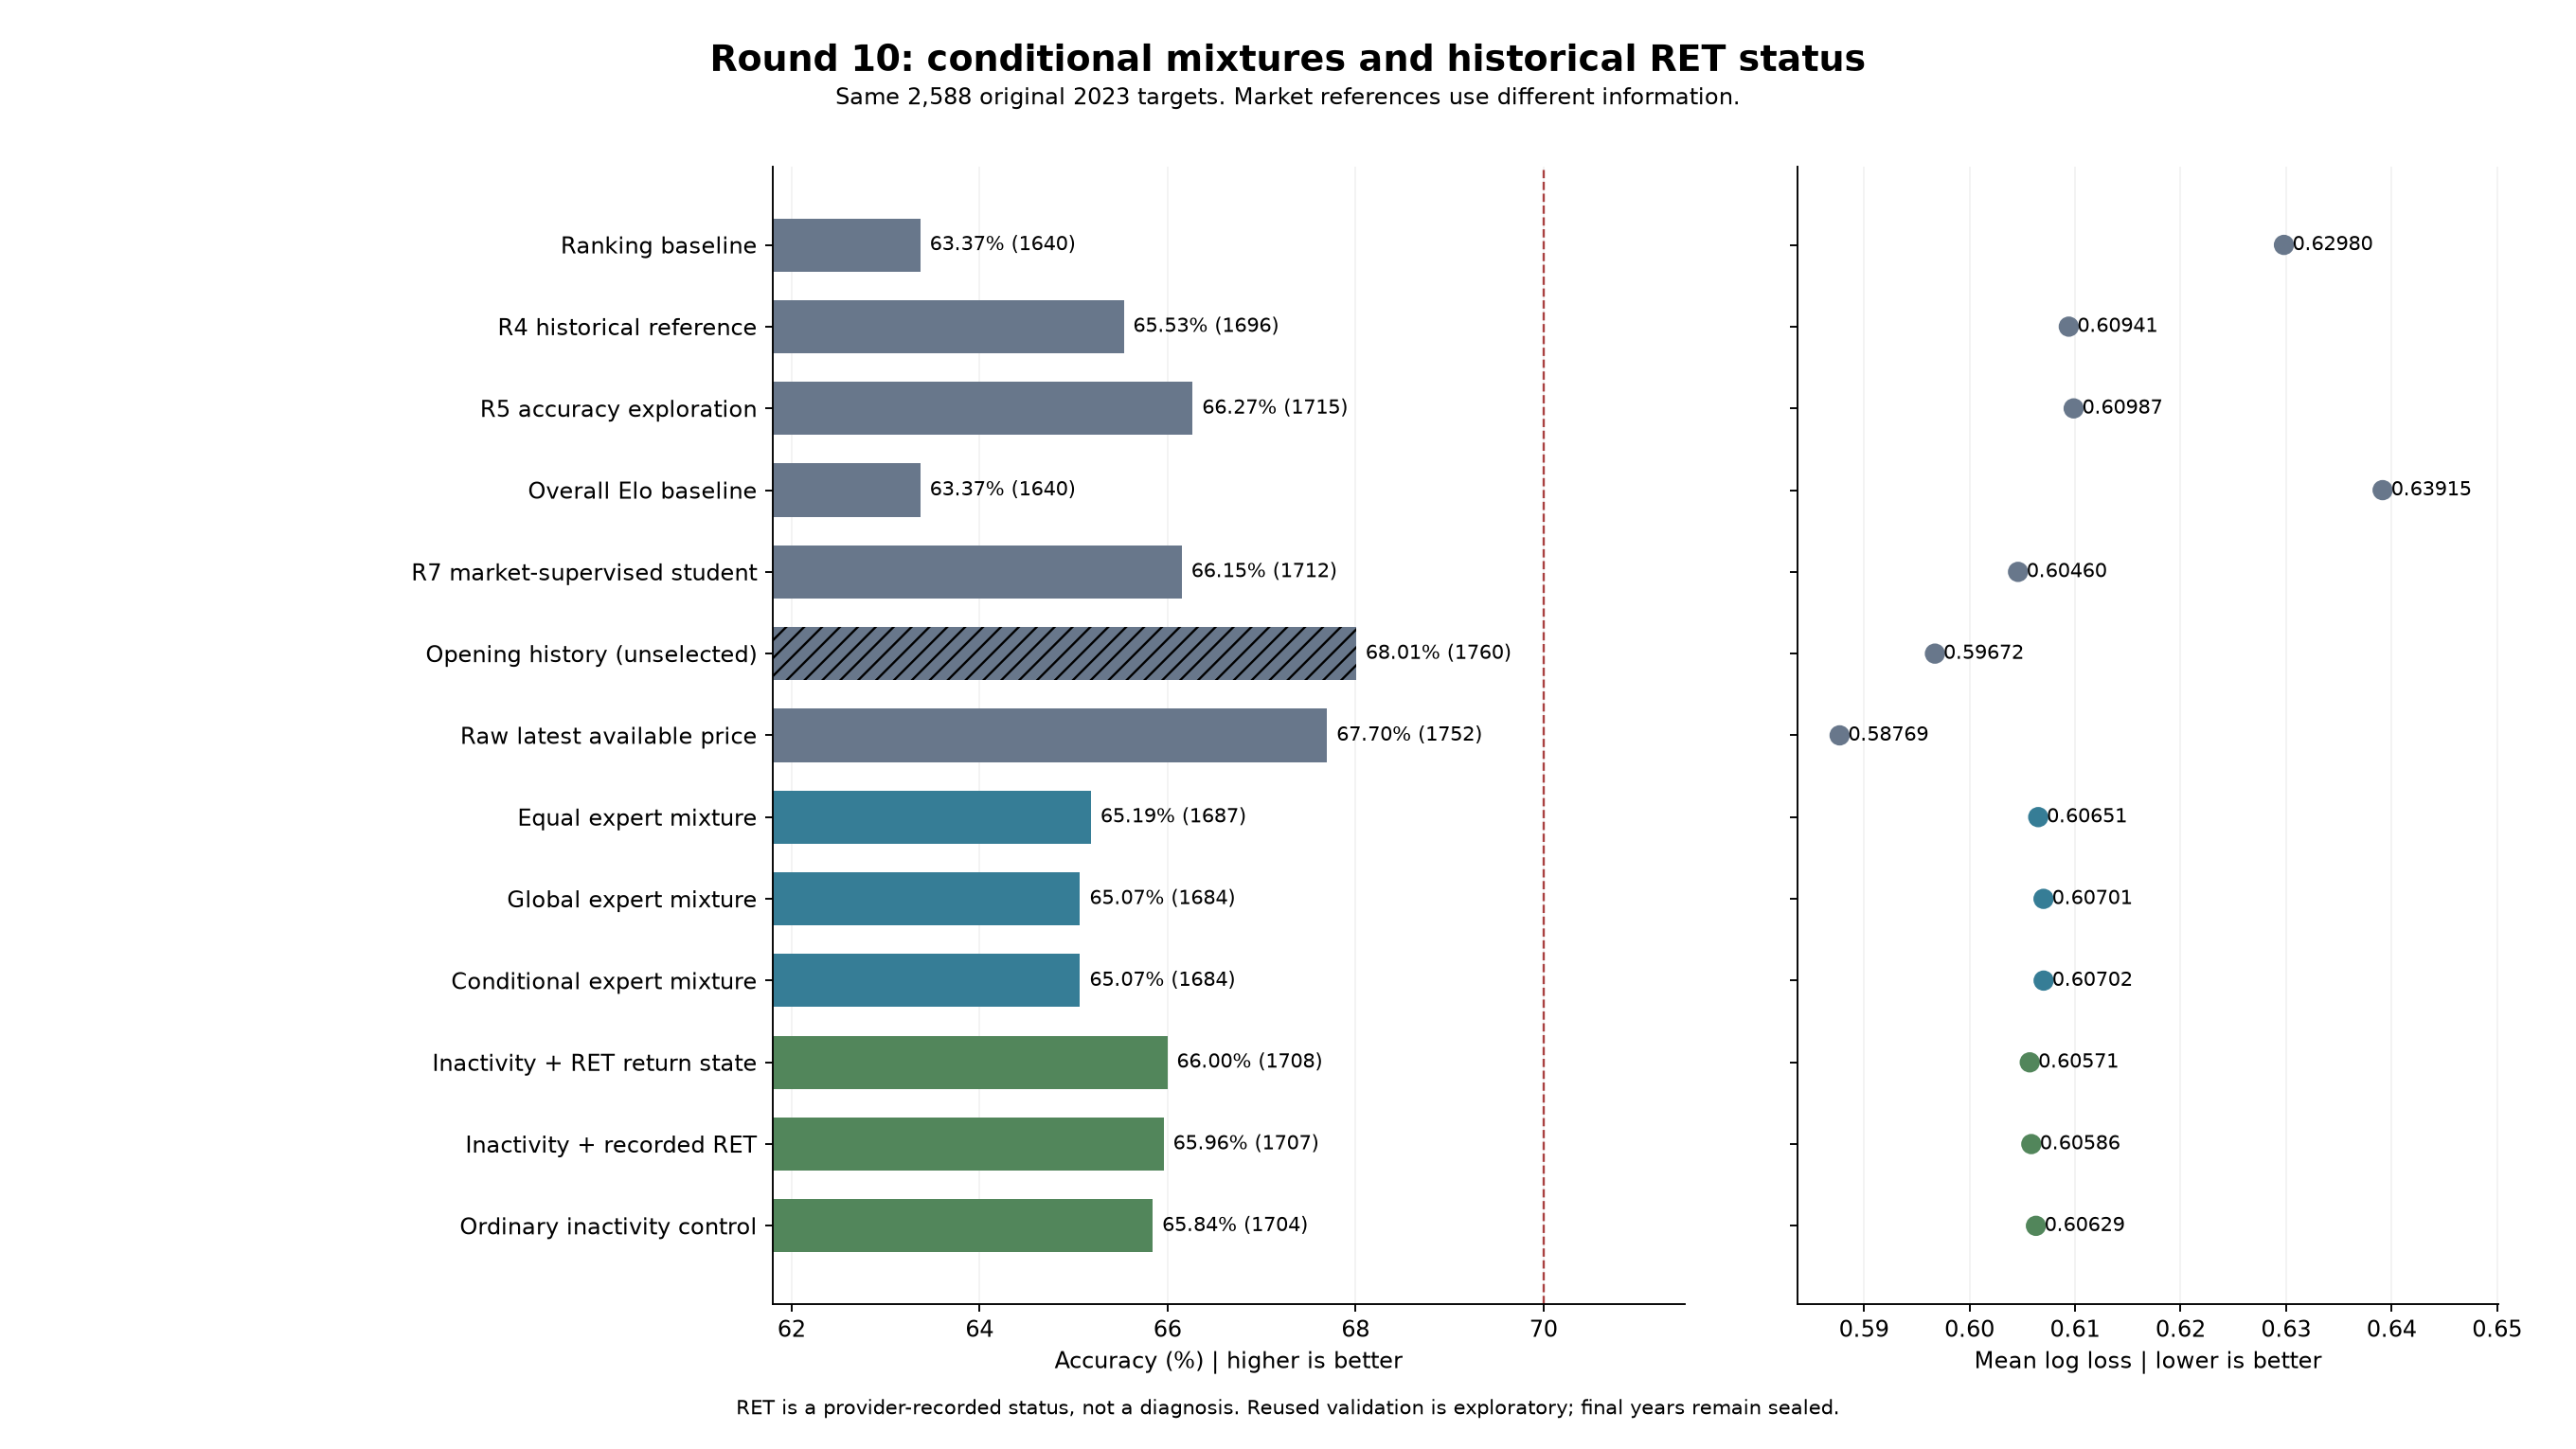

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
out=Path.cwd()/'results/round10'
table=pd.read_csv(out/'overview_comparison.csv')
assert table.matches.eq(2588).all()
display(table.loc[table.display,['branch','model','role','correct','accuracy','mean_log_loss']])
display(Image(filename=str(out/'round10_comparison.png')))

## 全部冻结比较
包含旧参考与所有新对照，不按2023重选。

In [2]:
with pd.option_context('display.max_rows',100,'display.max_colwidth',60):
    display(table[['branch','model','role','correct','accuracy','mean_log_loss']])

,branch,model,role,correct,accuracy,mean_log_loss
0,prior,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,prior,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,prior,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
3,prior,previous_round5_best_loss,R5：此前最低观察 loss 对照,1706,0.659196,0.606453
4,prior,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,prior,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
6,prior,history_linear_C0.03_alpha1,2023最高观察准确率，未选中，loss更差,1760,0.680062,0.596723
7,prior,raw_market,固定对照 / 既有模型；分支保留推荐,1752,0.676971,0.587691
8,gating,round4_reference,既有参考；2021冻结选择；分支保留/采用,1696,0.655332,0.609407
9,gating,equal_mix,预设新对照,1687,0.651855,0.606512


## 匹配对照与日期证据
来源可行性计数不代表预测提升。

In [3]:
import json
display(pd.read_csv(out/'gating/matched_routing.csv'))
display(pd.read_csv(out/'retirement/matched_controls.csv'))
ledger=json.loads((out/'completion/source_feasibility.json').read_text())
display(pd.DataFrame(ledger['cases'])[['source','target','date_bound_qualified','already_available_under_T_minus_21','target_matches','newly_covered_either_player']])

,period,matches,accuracy_improvement,log_loss_reduction,max_probability_change,mean_probability_change
0,2021,2388,0.001256,0.000152,0.017679,0.001821
1,2022,2528,-0.000791,0.000160,0.010448,0.001029
2,2023,2588,0.000000,-0.000010,0.007554,0.000427


,candidate,control,oof_accuracy_change,oof_loss_change,validation_accuracy_change,validation_loss_change
0,ret_R_spline,ret_I_spline,-0.000326,-0.000157,0.001159,-0.000439
1,ret_RC_spline,ret_I_spline,-0.000163,-0.000075,0.001546,-0.000587
2,ret_RC_spline,ret_R_spline,0.000163,0.000083,0.000386,-0.000148


,source,target,date_bound_qualified,already_available_under_T_minus_21,target_matches,newly_covered_either_player
0,2021-416,2021-520,True,True,123,0
1,2021-500,2021-540,True,False,123,60
2,2021-540,2021-316,False,False,26,0
3,2022-416,2022-520,True,False,124,99
4,2022-500,2022-540,True,False,122,45
5,2022-540,2022-316,False,False,26,0
